In [5]:
from google.colab import drive
drive.mount('/content/Drive')

Mounted at /content/Drive


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

In [7]:
data = pd.read_csv('/content/Drive/MyDrive/coffee_beans_dataset/coffee_roasting_dataset.csv')
print(data[:10])

   temperature_celsius  duration_minutes  good_roast
0           185.317638         12.693965           1
1           259.920475         11.867664           0
2           231.013571         14.414242           0
3           175.366645         11.720587           0
4           187.120865         14.129732           1
5           225.905864         12.100249           1
6           208.405157         14.177189           0
7           207.075931         14.032738           0
8           280.603854         14.232259           0
9           202.869352         12.249010           1


In [8]:
print(data.head())

   temperature_celsius  duration_minutes  good_roast
0           185.317638         12.693965           1
1           259.920475         11.867664           0
2           231.013571         14.414242           0
3           175.366645         11.720587           0
4           187.120865         14.129732           1


In [9]:
X = np.array(data[['temperature_celsius', 'duration_minutes']])
print(X.shape)
print(X[:10])

(200, 2)
[[185.31763812  12.69396457]
 [259.92047498  11.86766377]
 [231.01357101  14.41424211]
 [175.3666449   11.72058651]
 [187.12086467  14.12973206]
 [225.90586448  12.10024905]
 [208.40515676  14.17718919]
 [207.07593089  14.0327376 ]
 [280.60385359  14.23225929]
 [202.86935247  12.24901028]]


In [10]:
# X = data[['temperature_celsius', 'duration_minutes']]
# print(X.shape)
# print(X[:5])

# # this is still a pandas dataframe, but we want data in matrix form. so i'm not gonna use this approach.

In [11]:
X = data[['temperature_celsius', 'duration_minutes']].to_numpy()
print(X.shape)
print(X[:5])

(200, 2)
[[185.31763812  12.69396457]
 [259.92047498  11.86766377]
 [231.01357101  14.41424211]
 [175.3666449   11.72058651]
 [187.12086467  14.12973206]]


In [12]:
y = data[["good_roast"]].to_numpy()
print(y.shape)
print(y[:10])

(200, 1)
[[1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]]


In [28]:
# normalized features
norm_l = tf.keras.layers.Normalization(axis=-1)
norm_l.adapt(X)
X_normed = norm_l(X)
print(X_normed[:10])

tf.Tensor(
[[-0.8345548  -0.6528792 ]
 [ 1.0323056  -1.3851453 ]
 [ 0.3089395   0.8716251 ]
 [-1.0835686  -1.5154841 ]
 [-0.7894309   0.6194935 ]
 [ 0.18112455 -1.1790283 ]
 [-0.2568132   0.6615495 ]
 [-0.29007566  0.5335373 ]
 [ 1.5498862   0.7103532 ]
 [-0.39534092 -1.047197  ]], shape=(10, 2), dtype=float32)


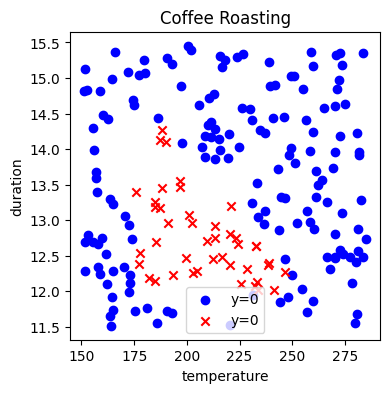

In [22]:
pos = (y.ravel() == 0)
neg = (y.ravel() == 1)

fig, ax = plt.subplots(1,1, figsize=(4,4))
ax.scatter(X[pos, 0], X[pos, 1], label='y=0', marker='o', c='b')
ax.scatter(X[neg, 0], X[neg, 1], label='y=0', marker='x', c='r')
ax.set_xlabel('temperature')
ax.set_ylabel('duration')
ax.set_title('Coffee Roasting')
ax.legend()
plt.show()

In [14]:
def sigmoid(z):
  g = 1 / (1 + np.exp(-z))
  return g

In [15]:
def dense_layer(a_in, W, b):
  units = W.shape[1]
  a_out = np.zeros(units)
  for j in range(units):
    w = W[:, j]
    z = np.dot(w, a_in) + b[j]
    a_out[j] = sigmoid(z)
  return a_out

In [16]:
def my_sequential(x, w1, b1, w2, b2):
  a1 = dense_layer(x, w1, b1)
  a2 = dense_layer(a1, w2, b2)
  return a2

In [17]:
W1_tmp = np.array( [[-8.93,  0.29, 12.9 ], [-0.1,  -7.32, 10.81]] )
b1_tmp = np.array( [-9.82, -9.28,  0.96] )
W2_tmp = np.array( [[-31.18], [-27.59], [-32.56]] )
b2_tmp = np.array( [15.41] )

In [18]:
def predict(x, w1, b1, w2, b2):
  m = x.shape[0]
  p = np.zeros((m, 1))
  for i in range(m):
    p[i, 0] = my_sequential(x[i], w1, b1, w2, b2)
  return p

In [30]:
X_test = np.array([[200,13.9],
    [200,17]])
X_test_normed = norm_l(X_test)
predictions = predict(X_test_normed, W1_tmp, b1_tmp, W2_tmp, b2_tmp)
print(predictions)

[[9.71931351e-01]
 [3.28978710e-08]]


/tmp/ipykernel_2000/3524833239.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  p[i, 0] = my_sequential(x[i], w1, b1, w2, b2)


In [31]:
y_hat = np.zeros_like(predictions)
for i in range(len(predictions)):
  if predictions[i] >= 0.5:
    y_hat[i] = 1
  else:
    y_hat[i] = 0

print(f"Decisions: {y_hat}")

Decisions: [[1.]
 [0.]]


In [32]:
# anothor way

y_hat = (predictions >= 0.5).astype(int)
print(y_hat)

[[1]
 [0]]
